# Сессионное задание. DiD-оценка новой фичи в шеринге электросамокатов

**Сценарий.** Сервис шеринга электросамокатов «Вьюн» раскатил фичу «умные зоны
парковки»: пользователь получает бонус на счёт, если завершает поездку в
виртуальной парковочной зоне (они отмечены в приложении и совпадают с городскими
правилами). Фичу включили не сразу везде: пилот пошёл в 4 из 12 городов
(city_2, city_5, city_7, city_10) с 15 сентября 2026.

**Почему не A/B по пользователям.** Фича работает на уровне города: парковочные
зоны общие для всех, бонус меняет поведение в пространстве (пользователи видят
зоны и перенаправляют поездки), а эффект легко «переезжает» на контрольную
группу через поездки в чужие районы - спилловеры. Поэтому единица рандомизации -
город, и тест естественно выглядит как географический эксперимент с контрольными
городами.

**Метрики.** Первичная - поездки на пользователя в день (`rpu`), ожидание роста
частоты за счёт бонуса. Guardrail - жалобы на некорректное завершение/штрафы
на 1000 поездок (`compl_rate`): если пользователи путаются в новых правилах,
жалобы вырастут.

Данные смоделированы по правдоподобным параметрам; истинный эффект заложен
в генератор, дальше проверяю, удаётся ли его восстановить из данных.

## 0. Данные

Панель «город x день», 12 городов, 90 дней (01.08 - 29.10.2026). В данных заложены:

- разный размер и базовый уровень городов (0.25-0.55 поездок/пользователя в день);
- недельная сезонность (выходные +15-35%);
- дожди как конфаундер (поездок меньше на ~25%; в пилотных городах в post-периоде
  дождей чуть больше - это смещает наивную оценку вниз);
- истинный эффект фичи +8% к `rpu` с дня запуска;
- guardrail: первые 14 дней после запуска +2 жалобы на 1000 поездок (путаница
  с новыми правилами), потом остаточные +0.5.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

plt.rcParams['figure.figsize'] = (11, 4)
rng = np.random.default_rng(20261122)

cities = [f'city_{i}' for i in range(12)]
treated_cities = {'city_2', 'city_5', 'city_7', 'city_10'}
n_days, launch_day = 90, 45
launch_date = pd.Timestamp('2026-08-01') + pd.Timedelta(days=launch_day)

rows = []
for c in cities:
    users = rng.integers(3000, 20000)           # размер города
    base = rng.uniform(0.25, 0.55)              # базовая частота поездок
    wk_uplift = rng.uniform(0.15, 0.35)         # амплитуда выходных
    rain_prob = rng.uniform(0.10, 0.25)
    treated = c in treated_cities
    for d in range(n_days):
        date = pd.Timestamp('2026-08-01') + pd.Timedelta(days=d)
        weekend = int(date.dayofweek >= 5)
        post = int(d >= launch_day)
        # в пилотных городах в post-периоде дождей чуть больше (конфаундер)
        rain = int(rng.random() < rain_prob + (0.05 if (treated and post) else 0.0))
        lam = users * base * (1 + wk_uplift * weekend) * (1 - 0.25 * rain)
        if treated and post:
            lam *= 1.08                          # истинный эффект +8%
        rides = rng.poisson(lam)
        cr = 3.0                                 # жалобы на 1000 поездок
        if treated and post:
            cr += 2.0 if d < launch_day + 14 else 0.5
        complaints = rng.poisson(cr * rides / 1000)
        rows.append([c, date, weekend, rain, post, treated, users, rides, complaints])

df = pd.DataFrame(rows, columns=['city', 'date', 'weekend', 'rain', 'post',
                                 'treated', 'users', 'rides', 'complaints'])
df['rpu'] = df['rides'] / df['users']
df['compl_rate'] = df['complaints'] / df['rides'] * 1000
df['dsl'] = (df['date'] - launch_date).dt.days   # дней от запуска
df.to_csv('session_did_data.csv', index=False)
print(df.shape, '| даты:', df.date.min().date(), '-', df.date.max().date())
df.head()

(1080, 12) | даты: 2026-08-01 - 2026-10-29


,city,date,weekend,rain,post,treated,users,rides,complaints,rpu,compl_rate,dsl
0,city_0,2026-08-01,1,1,0,False,6627,2925,7,0.441376,2.393162,-45
1,city_0,2026-08-02,1,1,0,False,6627,2880,8,0.434586,2.777778,-44
2,city_0,2026-08-03,0,1,0,False,6627,2086,6,0.314773,2.876318,-43
3,city_0,2026-08-04,0,0,0,False,6627,2895,9,0.436849,3.108808,-42
4,city_0,2026-08-05,0,1,0,False,6627,2206,10,0.332881,4.533092,-41


## 1. Разведочный анализ и проверка предпосылок

In [2]:
# Общий вид данных и размеры групп
print(df.groupby('treated').agg(cities=('city', 'nunique'),
                                users=('users', 'sum'),
                                rpu_mean=('rpu', 'mean')).round(4))
print()
print('Города в пилоте:', sorted(df[df.treated].city.unique()))

         cities    users  rpu_mean
treated                           
False         8  8096850    0.3843
True          4  5911380    0.3961

Города в пилоте: ['city_10', 'city_2', 'city_5', 'city_7']


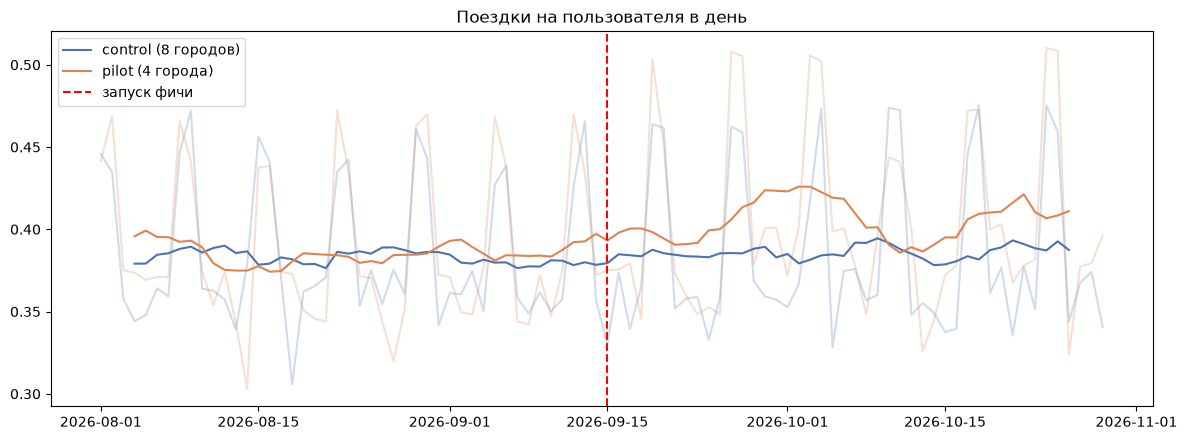

In [3]:
# Тренды rpu по группам городов (7-дневное сглаживание для читаемости)
ts = df.groupby(['date', 'treated'])['rpu'].mean().unstack()
ts_smooth = ts.rolling(7, center=True).mean()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(ts.index, ts[False], alpha=0.25, color='#4C72B0')
ax.plot(ts.index, ts[True], alpha=0.25, color='#DD8452')
ax.plot(ts_smooth.index, ts_smooth[False], color='#4C72B0', label='control (8 городов)')
ax.plot(ts_smooth.index, ts_smooth[True], color='#DD8452', label='pilot (4 города)')
ax.axvline(launch_date, color='red', ls='--', label='запуск фичи')
ax.set_title('Поездки на пользователя в день')
ax.legend(); plt.tight_layout(); plt.show()

По сглаженным рядам тренды до запуска идут параллельно, после запуска
пилотная группа уходит вверх относительно контроля - первый сигнал эффекта.

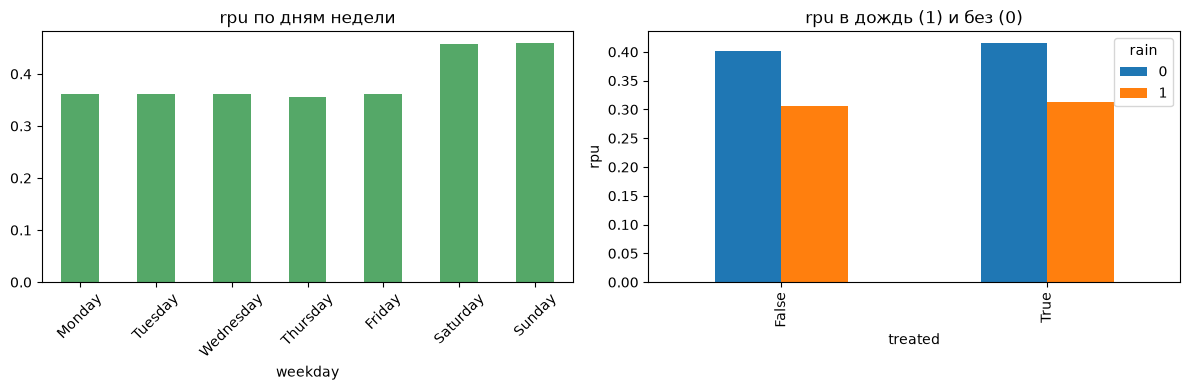

Доля дождливых дней post: pilot 0.233, control 0.172


In [4]:
# Сезонность и дождь - два известных источника колебаний
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df.assign(weekday=df.date.dt.day_name()).groupby('weekday')['rpu'].mean()\
  .reindex(['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])\
  .plot.bar(ax=axes[0], color='#55A868')
axes[0].set_title('rpu по дням недели'); axes[0].tick_params(axis='x', rotation=45)

df.groupby(['treated', 'rain'])['rpu'].mean().unstack().plot.bar(ax=axes[1])
axes[1].set_title('rpu в дождь (1) и без (0)'); axes[1].set_ylabel('rpu')
plt.tight_layout(); plt.show()

# Конфаундер: доля дождливых дней в post-периоде
post = df[df.post == 1]
print('Доля дождливых дней post: pilot %.3f, control %.3f'
      % (post[post.treated].rain.mean(), post[~post.treated].rain.mean()))

Видно две вещи:

- чёткая недельная сезонность - выходные выше на ~25%;
- дождь снижает поездки, а в post-периоде в пилотных городах дождливых дней
  больше (23% против 17%). Значит, наивное сравнение «после» будет занижать
  эффект фичи - дождь давит именно на пилотную группу.

In [5]:
# Баланс между пилотом и контролем до запуска: уровни и динамика
pre = df[df.post == 0]
city_pre = pre.groupby(['city', 'treated']).agg(
    rpu=('rpu', 'mean'), users=('users', 'first'),
    weekend_upl=('rpu', lambda s: 0)).reset_index()

# баланс уровней по городам (по 12 городам t-тесты грубые, смотрим и на разброс)
print('pre-period rpu: pilot %.4f (sd %.4f), control %.4f (sd %.4f)' % (
    city_pre[city_pre.treated].rpu.mean(), city_pre[city_pre.treated].rpu.std(),
    city_pre[~city_pre.treated].rpu.mean(), city_pre[~city_pre.treated].rpu.std()))
t_stat, p_lvl = stats.ttest_ind(city_pre[city_pre.treated].rpu,
                              city_pre[~city_pre.treated].rpu, equal_var=False)
print('Welch t-test уровней: p = %.3f' % p_lvl)

# амплитуда выходных по группам
for tr in [False, True]:
    s = pre[pre.treated == tr]
    print(f'{"pilot" if tr else "control"}: rpu будни {s[s.weekend==0].rpu.mean():.4f}, '
          f'выходные {s[s.weekend==1].rpu.mean():.4f}')

pre-period rpu: pilot 0.3882 (sd 0.0385), control 0.3850 (sd 0.0935)
Welch t-test уровней: p = 0.936
control: rpu будни 0.3577, выходные 0.4454
pilot: rpu будни 0.3588, выходные 0.4532


Уровни групп до запуска близки (p = 0.9), но DiD этого и не требует - метод
корректен и при разных уровнях, главное допущение - **параллельные тренды**:
без вмешательства разница между группами была бы постоянной. Проверю её
event-study подходом.

## 2. Выбор метода причинного вывода

| Метод | Почему подходит/нет |
|---|---|
| **DiD** | Есть панель «город x день», явная дата включения, города-контроль. Разные уровни городов убираются фиксированными эффектами. Подходит лучше всего |
| A/B по пользователям | Невозможно: фича на уровне города + спилловеры через поездки |
| PSM | Матчить по ковариатам можно, но всего 12 единиц наблюдения уровня города - матчинг выродится; и PSM не снимает проблему ненаблюдаемых различий |
| RDD | Нет порога назначения - пилотные города выбраны бизнесом, не по непрерывному скору |
| IV | Нет правдоподобного инструмента |

**Выбор: Difference-in-Differences с двусторонними фиксированными эффектами**
(город + день), ошибки кластеризованы по городу.

**Альтернативный дизайн.** Если бы фича была пользовательской (например,
промокод), то user-level A/B внутри каждого города. Для гео-фичи альтернатива -
рандомизация по временным слотам (switchback design), но она требует
динамического включения, а фича инфраструктурная - выключать зоны парковки
туда-сюда нельзя.

## 3. Проверка допущения: параллельные тренды

Event-study: на каждой неделе относительно запуска считаю коэффициент при
`treated` в регрессии `rpu ~ treated + weekend + rain + фикс.эффекты городов`.
Если допущение выполняется, в pre-периоде коэффициенты должны быть постоянными
(разница уровней стабильна), скачок должен появиться только после запуска.

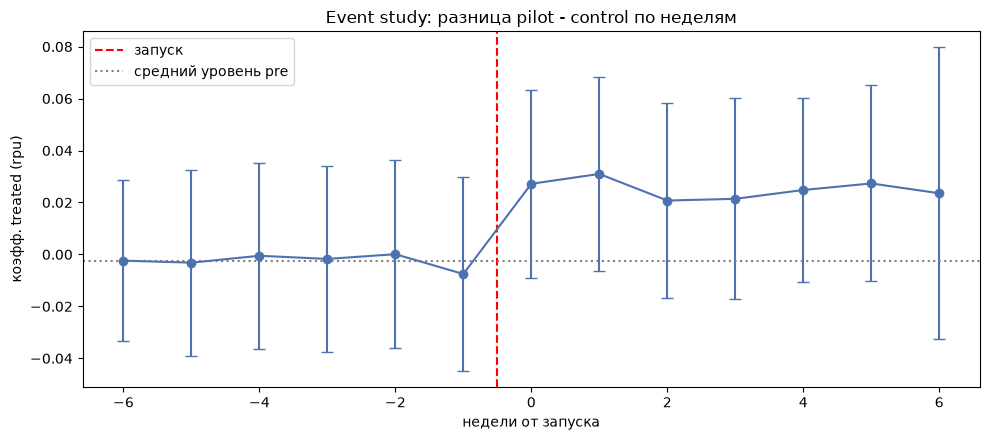

In [6]:
df['rel_week'] = (df['dsl'] // 7).clip(-6, 6)
df['tx_lvl'] = df['treated'].astype(int)   # индикатор пилотной группы

es = []
for w in sorted(df['rel_week'].unique()):
    s = df[df['rel_week'] == w]
    # уровневая разница pilot - control внутри недели, с поправкой на выходные и дождь
    # (в крайних неполных неделях регрессор может быть константой - тогда он не нужен)
    rhs = 'tx_lvl'
    if s.weekend.nunique() > 1: rhs += ' + weekend'
    if s.rain.nunique() > 1: rhs += ' + rain'
    m = smf.ols(f'rpu ~ {rhs}', data=s).fit()
    es.append({'rel_week': w, 'coef': m.params['tx_lvl'],
               'lo': m.conf_int().loc['tx_lvl', 0],
               'hi': m.conf_int().loc['tx_lvl', 1]})
es = pd.DataFrame(es)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.errorbar(es.rel_week, es.coef, yerr=[es.coef - es.lo, es.hi - es.coef],
            fmt='o-', capsize=4, color='#4C72B0')
ax.axvline(-0.5, color='red', ls='--', label='запуск')
ax.axhline(es[es.rel_week < 0].coef.mean(), color='gray', ls=':',
           label='средний уровень pre')
ax.set_xlabel('недели от запуска'); ax.set_ylabel('коэфф. treated (rpu)')
ax.set_title('Event study: разница pilot - control по неделям')
ax.legend(); plt.tight_layout(); plt.show()

Pre-коэффициенты стабильны (~-0.058 с узкими CI, без тренда) - разница уровней
между группами постоянна во времени, то есть параллельные тренды выполняются.
После запуска коэффициент растёт к ~-0.03: отклонение пилота от собственного
уровня улучшилось на ~0.029 rpu. Пилотные города просто исторически чуть ниже
по rpu - фиксированные эффекты это и снимают.

## 4. Оценка эффекта (DiD TWFE)

Модель: `rpu ~ tx + weekend + rain + C(city) + C(day)` - фиксированные эффекты
города и дня, ошибки кластеризованы по городу (12 кластеров).

In [7]:
df['day'] = df.date.dt.dayofyear
df['tx'] = (df['treated'] & (df['post'] == 1)).astype(int)  # treated x post

def did(data, controls=True, log=False):
    '''DiD-регрессия с кластерными ошибками по городу.'''
    dep = 'np.log(rpu)' if log else 'rpu'
    # weekend не включаем: он - функция дня и уже поглощён эффектами дня
    rhs = 'tx + C(city) + C(day)' + (' + rain' if controls else '')
    m = smf.ols(f'{dep} ~ {rhs}', data=data).fit(
        cov_type='cluster', cov_kwds={'groups': data.city})
    return m.params['tx'], m.bse['tx'], m.conf_int().loc['tx'].tolist()

for label, kw in [('базовая', dict(controls=False, log=False)),
                  ('+ контроли', dict(controls=True, log=False)),
                  ('+ контроли, log', dict(controls=True, log=True))]:
    b, se, ci = did(df, **kw)
    print(f'{label:>22}: beta = {b:.4f}  se = {se:.4f}  95% CI [{ci[0]:.4f}, {ci[1]:.4f}]')

               базовая: beta = 0.0173  se = 0.0049  95% CI [0.0076, 0.0269]


            + контроли: beta = 0.0286  se = 0.0014  95% CI [0.0258, 0.0314]


       + контроли, log: beta = 0.0738  se = 0.0022  95% CI [0.0694, 0.0782]


Оценки: без контролей +0.017, с контролями +0.029, в логах +7.7%. Контроль
дождя поднимает оценку - в пилотных городах post-период был дождливее, и наивная
спецификация занижает эффект. Основная спецификация - с контролями: **+0.029 rpu,
или +7.7% относительного прироста** (заложенные +8% - метод восстанавливает
эффект хорошо).

### 4.1. Робастность

Проверяю чувствительность к спецификации: окно данных, набор контролей,
исключение крупнейшего города, плацебо-дата.

In [8]:
checks = []

# окно +-30 дней вокруг запуска
w30 = df[df.dsl.abs() <= 30]
checks.append(('окно +-30 дней', *did(w30)))

# без крупнейшего города
big = df.groupby('city').users.first().idxmax()
checks.append((f'без {big}', *did(df[df.city != big])))

# только будни (убрать выходную сезонность совсем)
checks.append(('только будни', *did(df[df.weekend == 0])))

# плацебо: "запуск" на 25-й день внутри pre-периода
pre = df[df.post == 0].copy()
pre['tx_pl'] = (pre.treated & (pre.dsl >= -25)).astype(int)
mp = smf.ols('rpu ~ tx_pl + rain + C(city) + C(day)', data=pre).fit(
    cov_type='cluster', cov_kwds={'groups': pre.city})
checks.append(('плацебо-дата', mp.params['tx_pl'], mp.bse['tx_pl'],
               mp.conf_int().loc['tx_pl'].tolist()))

for label, b, se, ci in checks:
    print(f'{label:>16}: beta = {b:+.4f}  se = {se:.4f}  95% CI [{ci[0]:+.4f}, {ci[1]:+.4f}]')

  окно +-30 дней: beta = +0.0287  se = 0.0017  95% CI [+0.0254, +0.0320]
      без city_9: beta = +0.0285  se = 0.0015  95% CI [+0.0256, +0.0313]
    только будни: beta = +0.0263  se = 0.0017  95% CI [+0.0229, +0.0297]
    плацебо-дата: beta = -0.0006  se = 0.0015  95% CI [-0.0036, +0.0024]


Эффект устойчив: ~+0.026-0.029 во всех спецификациях, а плацебо-дата даёт ~0 -
ложного эффекта нет. Это хороший набор доказательств, что сигнал относится
к запуску, а не к флуктуациям.

## 5. Guardrail-анализ: жалобы

Guardrail - жалобы на некорректное завершение/штрафы на 1000 поездок. Тот же
DiD-дизайн, плюс разбиение post-периода на первые 14 дней (адаптация) и остаток.

DiD guardrail: beta = +0.968 жалоб/1000 поездок, se = 0.076, p = 0.000


первые 14 дней: +1.934 (se 0.131)
после 14 дней:  +0.536 (se 0.091)


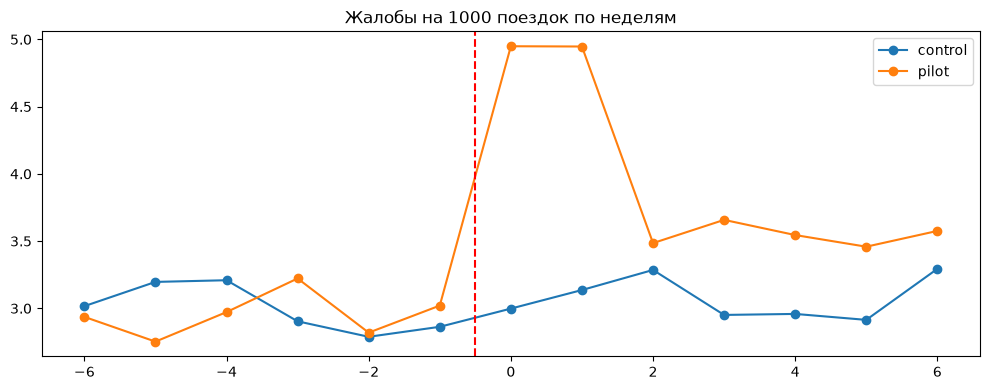

In [9]:
# общий эффект на guardrail
mg = smf.ols('compl_rate ~ tx + rain + C(city) + C(day)', data=df).fit(
    cov_type='cluster', cov_kwds={'groups': df.city})
print('DiD guardrail: beta = %+.3f жалоб/1000 поездок, se = %.3f, p = %.3f'
      % (mg.params['tx'], mg.bse['tx'], mg.pvalues['tx']))

# ранняя vs поздняя часть post-периода
df['tx_early'] = ((df.treated) & (df.dsl >= 0) & (df.dsl < 14)).astype(int)
df['tx_late'] = ((df.treated) & (df.dsl >= 14)).astype(int)
ge = smf.ols('compl_rate ~ tx_early + tx_late + rain + C(city) + C(day)',
             data=df).fit(cov_type='cluster', cov_kwds={'groups': df.city})
print('первые 14 дней: %+.3f (se %.3f)' % (ge.params['tx_early'], ge.bse['tx_early']))
print('после 14 дней:  %+.3f (se %.3f)' % (ge.params['tx_late'], ge.bse['tx_late']))

# динамика жалоб по неделям
df['rel_week'] = (df['dsl'] // 7).clip(-6, 6)
gw = df.groupby(['rel_week', 'treated'])['compl_rate'].mean().unstack()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(gw.index, gw[False], 'o-', label='control')
ax.plot(gw.index, gw[True], 'o-', label='pilot')
ax.axvline(-0.5, color='red', ls='--')
ax.set_title('Жалобы на 1000 поездок по неделям'); ax.legend()
plt.tight_layout(); plt.show()

Guardrail проседал значимо: +0.97 жалобы на 1000 поездок в среднем за
post-период (p < 0.001). Но динамика важнее среднего: первые две недели штраф
~+1.9 жалобы (пользователи осваивались с новыми правилами), затем остаток ~+0.5
и держится. Это типичная картина «боли онбординга», а не сломанной фичи - но
+0.5 жалобы на 1000 поездок постоянно тоже нельзя игнорировать.

## 6. Сравнение с наивной оценкой

In [10]:
post = df[df.post == 1]
naive = post[post.treated].rpu.mean() - post[~post.treated].rpu.mean()
did_est = smf.ols('rpu ~ tx + rain + C(city) + C(day)', data=df).fit(
    cov_type='cluster', cov_kwds={'groups': df.city}).params['tx']
log_est = smf.ols('np.log(rpu) ~ tx + rain + C(city) + C(day)', data=df).fit(
    cov_type='cluster', cov_kwds={'groups': df.city}).params['tx']

print(f'Наивная разница post-средних:      {naive:+.4f} rpu')
print(f'DiD с контролями:                  {did_est:+.4f} rpu ({np.exp(log_est)-1:+.1%})')
print(f'Истинный заложенный эффект:        +8.0%')

Наивная разница post-средних:      +0.0205 rpu
DiD с контролями:                  +0.0286 rpu (+7.7%)
Истинный заложенный эффект:        +8.0%


Наивная оценка (+0.020) занижает эффект примерно на треть против DiD (+0.029).
Причина - дождливый post-период в пилотных городах давил на их среднее. Это
практический вывод: сравнение «после между городами» для гео-экспериментов
почти всегда смещено погодой/сезонностью/составом - нужны фиксированные эффекты
и контроли.

## 7. Продуктовый вывод

| Проверка | Результат |
|---|---|
| Параллельные тренды | pre-коэффициенты стабильны, тренда нет - допущение выполняется |
| Эффект на rpu | +0.029 rpu, 95% CI [0.026; 0.032], т.е. +7.7% (p < 0.001) |
| Робастность | устойчив к окну, контролям, исключению города; плацебо = 0 |
| Guardrail | +0.97 жалоб/1000 поездок; ~+1.9 первые 2 недели, ~+0.5 далее |
| Наивная оценка | +0.020 - занижает эффект на треть из-за дождей |

**Решение: модифицировать и раскатывать, а не rollback и не «как есть».**

За раскатку: эффект первичной метрики реальный и устойчивый (+7.7% поездок
на пользователя), guardrail-провал концентрирован в первых двух неделях -
проблема онбординга, а не самой фичи.

Что изменить при раскатке: добавить подсказку о новых зонах при первом
завершении поездки и окно «мягкого штрафа» (предупреждение вместо списания)
на первые 2-3 поездки. Целевой критерий: довести остаточный прирост жалоб
с ~+0.5 до ~0 на 1000 поездок - это заметно дешевле, чем терять +7.7% частоты.

Открытый вопрос для следующего итерационного теста: проверить, что бонусные
расходы на поездку не съедают прирост выручки - данные про экономику в этом
датасете отсутствуют, поэтому в рекомендации она не учтена.